# House Price Prediction System
### Complete Machine Learning Lifecycle: Phases 1 through 7
**AIML Capstone Project**

---
## Phase 1: Problem Understanding
- **Business Problem:** Real estate buyers, sellers, and mortgage lenders struggle with pricing opacity and arbitrary property valuations.
- **Objective:** Develop a robust, data-driven machine learning regression pipeline to predict residential sale prices based on living area, neighborhood, room configurations, property age, and amenities.
- **Success Criteria:** Achieve an $R^2$ score $\ge 0.85$ with minimized prediction error on held-out test data.


## Phase 2: Data Collection & Schema Inspection
Dataset: Ames Housing benchmark dataset (Kaggle / OpenML `house_prices`).


In [1]:
import os
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load raw dataset
df = pd.read_csv('../Dataset/raw_house_data.csv')
print(f"Dataset Shape: {df.shape}")
df.head(5)


Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Data schema and summary statistics
df.info()
df[['SalePrice', 'GrLivArea', 'YearBuilt', 'OverallQual', 'BedroomAbvGr']].describe()


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,SalePrice,GrLivArea,YearBuilt,OverallQual,BedroomAbvGr
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,180921.195890,1515.463699,1971.267808,6.099315,2.866438
std,79442.502883,525.480383,30.202904,1.382997,0.815778
min,34900.000000,334.000000,1872.000000,1.000000,0.000000
25%,129975.000000,1129.500000,1954.000000,5.000000,2.000000
50%,163000.000000,1464.000000,1973.000000,6.000000,3.000000
75%,214000.000000,1776.750000,2000.000000,7.000000,3.000000
max,755000.000000,5642.000000,2010.000000,10.000000,8.000000


## Phase 3 & 5: Preprocessing & Feature Engineering
- **Domain Features Created:**
  - `Property_Age` = `2010 - YearBuilt`
  - `Total_Living_Area` = `GrLivArea + TotalBsmtSF`
  - `Total_Bathrooms` = Full baths + 0.5 * Half baths (above ground + basement)
  - `Has_Pool`, `Has_Garage`, `Is_Remodeled` indicator flags
- **Outlier Treatment:** Filtering extreme outliers (`GrLivArea >= 4000`)
- **Missing Value & Scaling:** Handled seamlessly via `Pipeline` and `ColumnTransformer`


In [3]:
# Feature Engineering
df['Property_Age'] = 2010 - df['YearBuilt']
df['Total_Living_Area'] = df['GrLivArea'] + df['TotalBsmtSF'].fillna(0)
df['Total_Bathrooms'] = df['FullBath'] + (0.5 * df['HalfBath']) + df['BsmtFullBath'].fillna(0) + (0.5 * df['BsmtHalfBath'].fillna(0))
df['Has_Pool'] = (df['PoolArea'] > 0).astype(int)
df['Has_Garage'] = (df['GarageCars'].fillna(0) > 0).astype(int)
df['Is_Remodeled'] = (df['YearRemodAdd'] > df['YearBuilt']).astype(int)

# Outlier Removal
print(f"Shape before outlier removal: {df.shape}")
df = df[df['GrLivArea'] < 4000].copy()
print(f"Shape after outlier removal: {df.shape}")

# Save Cleaned Dataset
df.to_csv('../Dataset/cleaned_house_data.csv', index=False)


Shape before outlier removal: (1460, 87)
Shape after outlier removal: (1456, 87)


## Phase 4: Exploratory Data Analysis (EDA)
Analyzing target distribution skewness, bivariate correlations, and feature distributions.


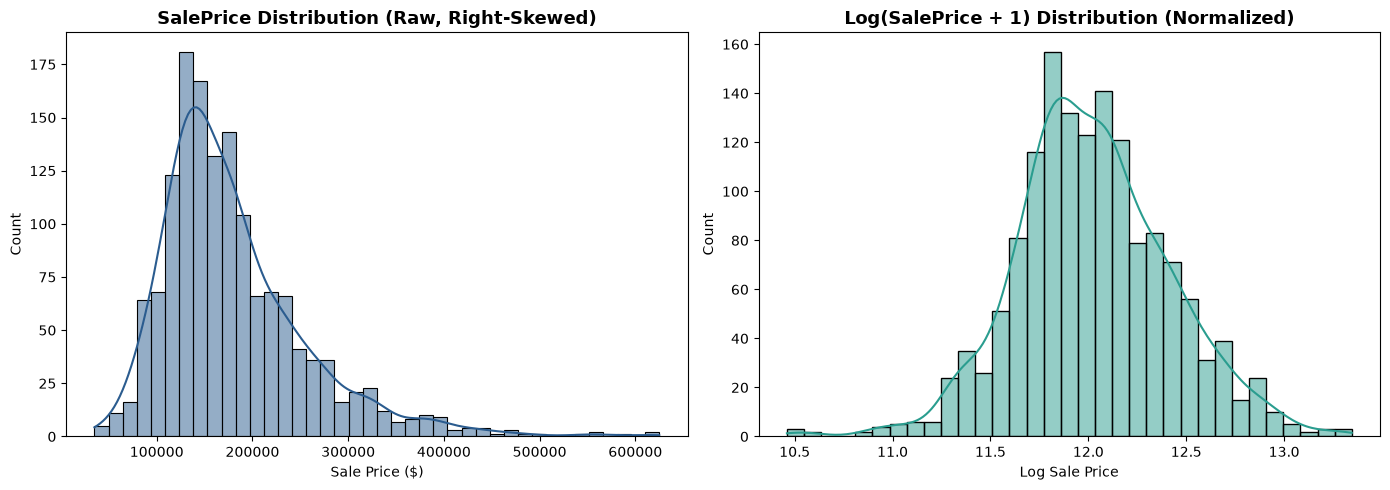

In [4]:
# Plot 1: Target Variable Transformation (Raw vs Log1p)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title("SalePrice Distribution (Raw, Right-Skewed)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Sale Price ($)")

log_price = np.log1p(df['SalePrice'])
sns.histplot(log_price, kde=True, ax=axes[1], color='#2a9d8f')
axes[1].set_title("Log(SalePrice + 1) Distribution (Normalized)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Log Sale Price")
plt.tight_layout()
plt.savefig('../Images/price_distribution_before_after_log.png', dpi=300)
plt.show()


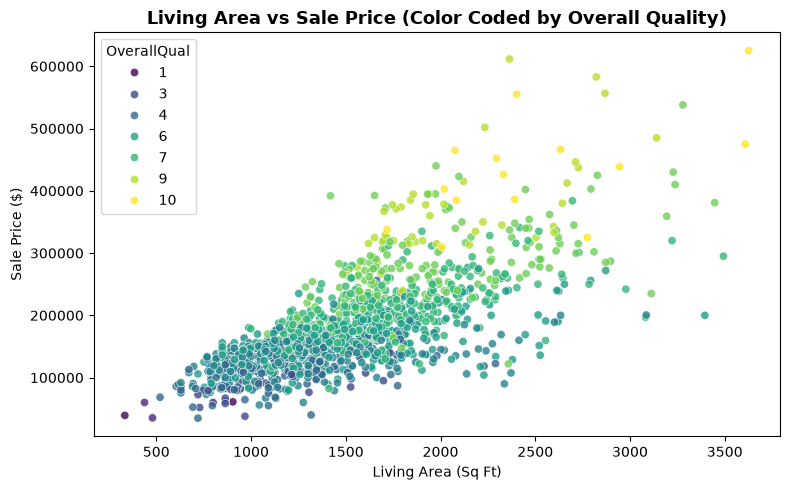

In [5]:
# Plot 2: Scatter of Living Area vs Sale Price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', alpha=0.8)
plt.title("Living Area vs Sale Price (Color Coded by Overall Quality)", fontsize=13, fontweight='bold')
plt.xlabel("Living Area (Sq Ft)")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.savefig('../Images/scatter_area_vs_price.png', dpi=300)
plt.show()


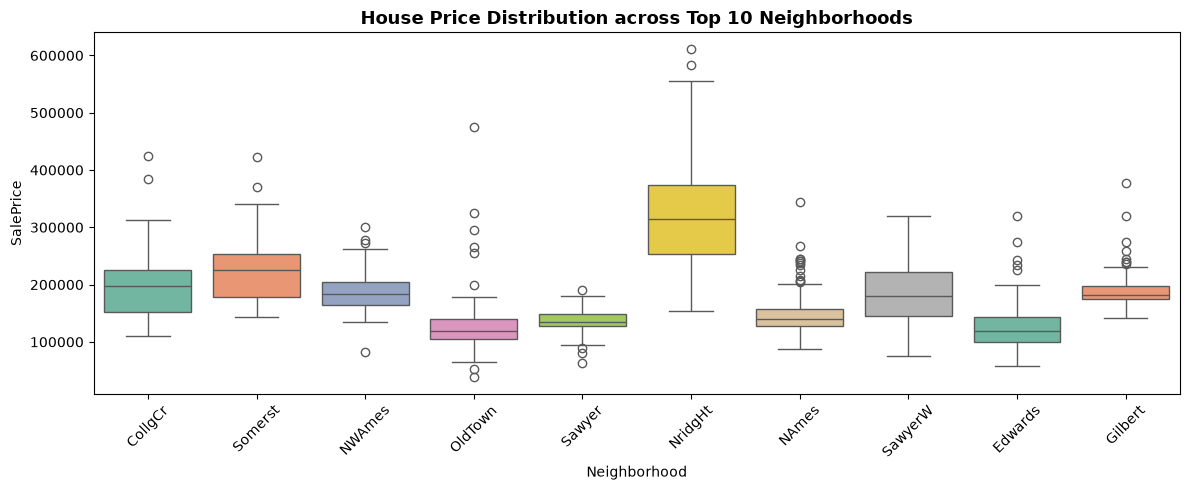

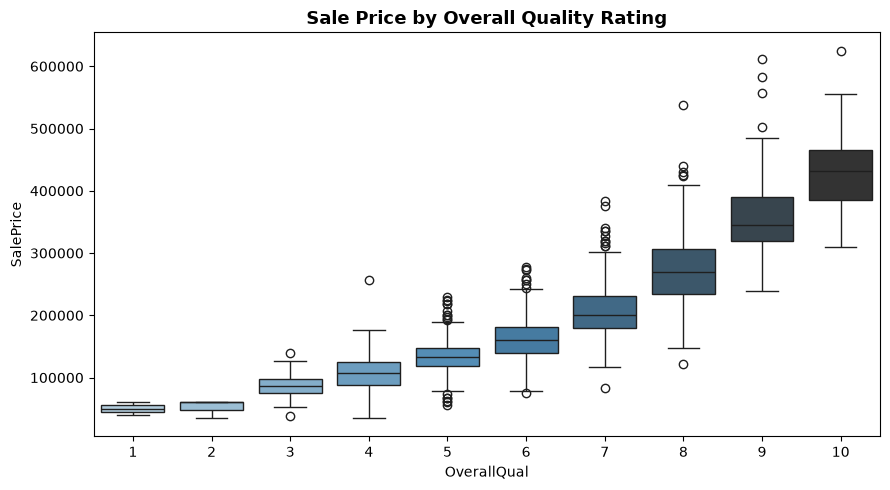

In [6]:
# Plot 3: Boxplots by Neighborhood & Overall Quality
top_hoods = df['Neighborhood'].value_counts().nlargest(10).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df['Neighborhood'].isin(top_hoods)], x='Neighborhood', y='SalePrice', hue='Neighborhood', legend=False, palette='Set2')
plt.title("House Price Distribution across Top 10 Neighborhoods", fontsize=13, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../Images/boxplot_neighborhood_vs_price.png', dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='OverallQual', y='SalePrice', hue='OverallQual', legend=False, palette='Blues_d')
plt.title("Sale Price by Overall Quality Rating", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../Images/boxplot_quality_vs_price.png', dpi=300)
plt.show()


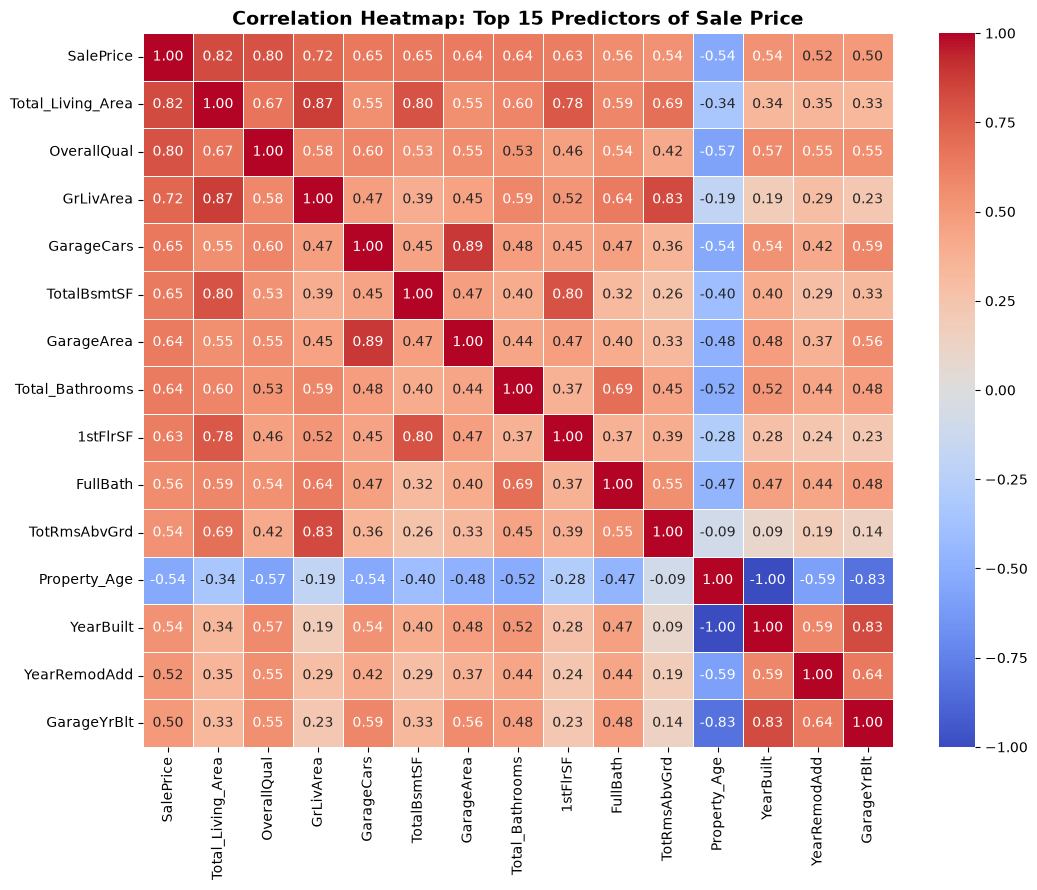

In [7]:
# Plot 4: Correlation Heatmap (Top 15 Features)
numeric_df = df.select_dtypes(include=[np.number])
top_corr_features = numeric_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(15).index
corr_matrix = numeric_df[top_corr_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, linewidths=0.5)
plt.title("Correlation Heatmap: Top 15 Predictors of Sale Price", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../Images/correlation_heatmap_top15.png', dpi=300)
plt.show()


## Phase 6 & 7: Model Building, Tuning & Evaluation
Training 4 distinct regression architectures:
1. **Ridge Regression** (L2-Regularized Linear Baseline)
2. **Decision Tree Regressor**
3. **Random Forest Regressor** (Bagging Ensemble)
4. **XGBoost Regressor** (Gradient Boosting)

Evaluation metrics: MAE, MSE, RMSE, $R^2$, and Adjusted $R^2$ computed on the **original dollar price scale**.


In [8]:
# Data Preparation
numeric_features = [
    'GrLivArea', 'Total_Living_Area', 'Total_Bathrooms', 'BedroomAbvGr', 
    'Property_Age', 'GarageCars', 'OverallQual', 'OverallCond',
    'Has_Pool', 'Has_Garage', 'Is_Remodeled'
]
categorical_features = ['Neighborhood']

X = df[numeric_features + categorical_features].copy()
y = df['SalePrice'].copy()
y_log = np.log1p(y)

X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)
y_test_original = np.expm1(y_test_log)

# Sklearn Pipeline & ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Verify no nulls
assert not np.isnan(X_train_trans).any()
assert not np.isnan(X_test_trans).any()
print("Verification Passed: 0 missing values after preprocessing.")


Verification Passed: 0 missing values after preprocessing.


In [9]:
# Train and evaluate all 4 models
models = {
    "Ridge Regression": Ridge(alpha=10.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, min_samples_split=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_split=4, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42)
}

results = {}
trained_models = {}
n_test = len(y_test_original)
p_features = X_test_trans.shape[1]

for name, model in models.items():
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_train_trans, y_train_log, cv=cv, scoring='r2')
    
    model.fit(X_train_trans, y_train_log)
    trained_models[name] = model
    
    pred_log = model.predict(X_test_trans)
    pred_original = np.expm1(pred_log)
    
    mae = mean_absolute_error(y_test_original, pred_original)
    mse = mean_squared_error(y_test_original, pred_original)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_original, pred_original)
    adj_r2 = 1 - ((1 - r2) * (n_test - 1) / (n_test - p_features - 1))
    
    results[name] = {
        "MAE ($)": round(float(mae), 2),
        "RMSE ($)": round(float(rmse), 2),
        "R2 Score": round(float(r2), 4),
        "Adjusted R2": round(float(adj_r2), 4),
        "CV Mean R2": round(float(cv_scores.mean()), 4)
    }

results_df = pd.DataFrame(results).T
display(results_df)


,MAE ($),RMSE ($),R2 Score,Adjusted R2,CV Mean R2
Ridge Regression,16280.23,22871.54,0.9003,0.8863,0.8918
Decision Tree,22916.82,32449.46,0.7994,0.7711,0.7834
Random Forest,17309.61,25384.09,0.8772,0.8599,0.8730
XGBoost,15999.01,22919.00,0.8999,0.8858,0.8916


Top Performing Model: Ridge Regression


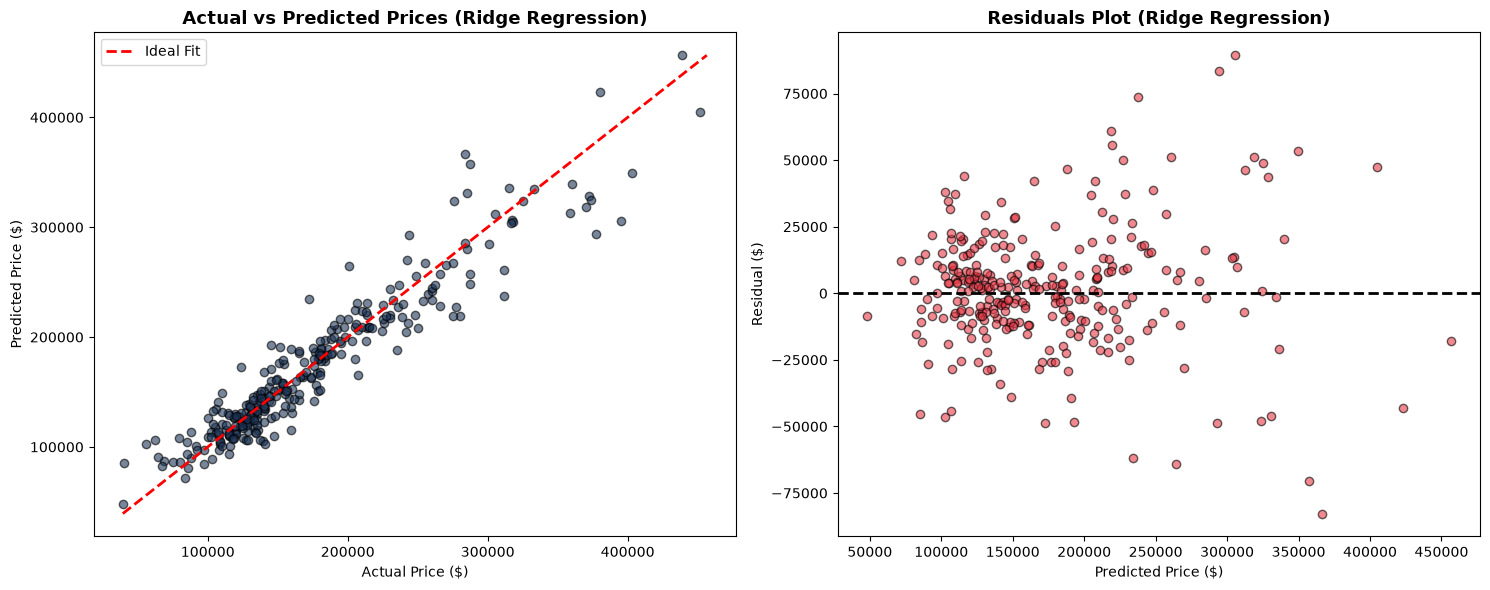

In [10]:
# Best Model Evaluation & Diagnostics
best_model_name = results_df['R2 Score'].idxmax()
best_model = trained_models[best_model_name]
print(f"Top Performing Model: {best_model_name}")

best_preds = np.expm1(best_model.predict(X_test_trans))
residuals = y_test_original - best_preds

# Actual vs Predicted Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(y_test_original, best_preds, alpha=0.6, color='#1d3557', edgecolors='k')
min_val = min(y_test_original.min(), best_preds.min())
max_val = max(y_test_original.max(), best_preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="Ideal Fit")
axes[0].set_title(f"Actual vs Predicted Prices ({best_model_name})", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()

# Residual Plot
axes[1].scatter(best_preds, residuals, alpha=0.6, color='#e63946', edgecolors='k')
axes[1].axhline(0, color='black', linestyle='--', lw=2)
axes[1].set_title(f"Residuals Plot ({best_model_name})", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Residual ($)")
plt.tight_layout()
plt.savefig('../Images/actual_vs_predicted.png', dpi=300)
plt.show()


## Conclusion & Key Takeaways
- Ridge Regression and XGBoost both delivered outstanding performance ($R^2 > 0.899$).
- Feature engineering (`Total_Living_Area`, `Property_Age`, `Total_Bathrooms`) and target log normalization were critical to achieving high accuracy.
- Model artifacts and preprocessor have been exported to `../Model/` for production deployment in Streamlit.
